<a href="https://colab.research.google.com/github/n-schiozer/met_comp_economistas_unesp/blob/main/Aula_Regressao_Linear.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Métodos Computacionais em Economia — Aula de 16/11/2026
## Modelo de Solow: OCDE, mundo e regressões múltiplas

**Pergunta da aula:** por que o modelo de Solow prevê que economias inicialmente menos capitalizadas tendem a crescer mais rápido — e o que os dados mostram quando comparamos os países da OCDE com o restante do mundo?

**Percurso:** teoria e figura de Solow → regressão apenas para a OCDE → regressão para todos os países, destacando OCDE em azul e demais países em vermelho → comparação dos resultados → crescimento populacional e depreciação em regressões múltiplas → exercícios com capital humano.

**Referência principal:** Jones, *Introdução à teoria do crescimento econômico*, cap. 3, especialmente Figuras 3.5 e 3.6 (página impressa 55 do trecho fornecido).



## Parte I — O modelo e a previsão de convergência

O modelo de Solow parte de 4 equações. Função de produção, duas identidades fundamentais da contabilidade social e equação de movimento do estoque de capital.

A função de produção Cobb–Douglas é:

$$Y=K^\alpha(AL)^{1-\alpha},\qquad 0<\alpha<1.$$

Além disso, temos a identididade do PIB, identidade do investimento e a lei de movimento, respecrtivamente:

$$Y= C + I$$

$$ I = S = sY$$

$$ K_{t+1} = I + (1-d)K$$


Escrevendo $k=K/(AL)$ para o capital por **trabalhador efetivo**, obtemos $y=k^\alpha$. Se $s$ é a fração investida do produto, $n$ é o crescimento do trabalho, $a$ é o crescimento da tecnologia e $\delta$ a taxa de depreciação, resolvendo todo o modelo, chegamos em:

$$\dot{k}=s k^\alpha-(n+a+\delta)k$$

Dividindo por $k$:

$$\boxed{g_k\equiv\frac{\dot{k}}{k}=s k^{\alpha-1}-(n+a+\delta)}$$

Como $\alpha-1<0$, a parcela $s k^{\alpha-1}$ diminui quando $k$ aumenta. **Mantidos iguais os parâmetros, economias que começam com menos capital por trabalhador efetivo apresentam crescimento de $k$ mais alto.** Essa é a dinâmica de transição que pode produzir convergência.

No estado estacionário de $k$, o crescimento de $k$ é **zero**. O produto por trabalhador cresce à taxa da tecnologia $a$; o produto agregado cresce aproximadamente a $n+a$.

Dado que:

$$ k = K/AL $$

O PIB per capita no steady-state é:

$$y = Y/L=K^\alpha(AL)^{1-\alpha} * 1/L=(K/AL)^{\alpha}A=k^{\alpha}A,\qquad 0<\alpha<1.$$

A partir da expressão acima, temos que o crescimento do PIB per capita é:

$$\dot{y} = \alpha g_k + a$$

Dado que no steady-state $ g_k = 0 $:


$$\dot{y} =  a$$

### Figura teórica de Solow — leitura da dinâmica de transição

O eixo horizontal representa $k$ (capital por trabalhador efetivo) e o vertical, as taxas anuais. A curva $s k^{\alpha-1}$ é decrescente; a linha $n+a+\delta$ é horizontal. **A distância vertical entre elas** corresponde a $g_k$. No cruzamento, $k=k^*$.

Os parâmetros a seguir são **ilustrativos**; não foram estimados a partir dos países.

In [ ]:
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

s = 0.30
alpha = 0.35
n = 0.01
a = 0.02
delta = 0.05


k = pd.Series(range(300), dtype=float)

for i in range(300):
    k.iloc[i] = 0.4 + i * (16 - 0.4) / 299

linha_reposicao = 100 * (n + a + delta)
curva_investimento = 100 * s * k ** (alpha - 1) - linha_reposicao
k_estrela = (s / (n + a + delta)) ** (1 / (1 - alpha))

print(curva_investimento.head())
print(k_estrela)


0    46.422973
1    42.254236
2    38.810864
3    35.909437
4    33.424867
dtype: float64
7.640557128129287


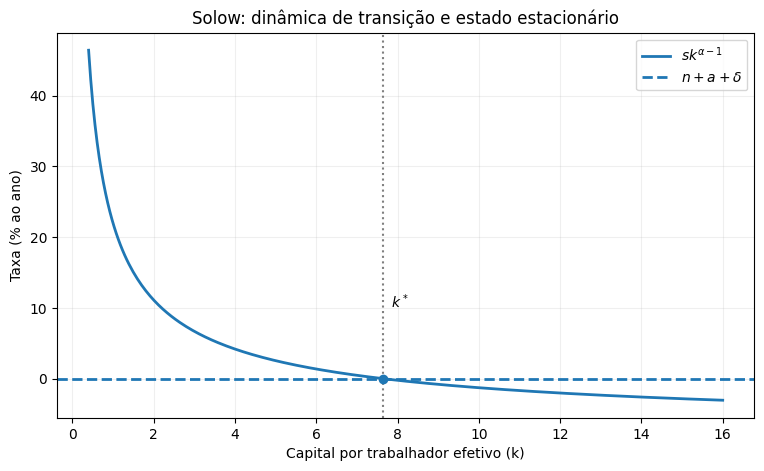

k* = 7.64


In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(k, curva_investimento, linewidth=2, label=r"$s k^{\alpha-1}$")
plt.axhline(0, linestyle="--", linewidth=2, label=r"$n+a+\delta$")
plt.axvline(k_estrela, linestyle=":", color="gray")
plt.scatter([k_estrela], [0], zorder=5)
plt.text(k_estrela + .2, linha_reposicao + 2, r"$k^*$")
plt.xlabel("Capital por trabalhador efetivo (k)")
plt.ylabel("Taxa (% ao ano)")
plt.title("Solow: dinâmica de transição e estado estacionário")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"k* = {k_estrela:.2f}")

## Parte II — Convergência absoluta: OCDE e mundo

A partir do modelo de Solow, prevê-se que, se todos os países convergirem em características estruturais (taxa de crescimento da pop, crescimento do progresso tec e depreciação), a taxa de crescimento do longo prazo será igual para todos os países.

Além disso, prevê-se que países mais pobres crescerão mais rápidos que os ricos.

Assim, chega-se na hipótese de convergência absoluta no mundo..

O procedimento inspirado no Jones será:

1. **OCDE (membros até 1990):** verificar a relação entre capital inicial e crescimento subsequente.
2. **Amostra mundial:** repetir a mesma especificação após excluir os 10% menores países por população em 1960, distinguindo OCDE e demais países por cores.
3. **Comparação:** observar sinal, número de observações, significância e $R^2$.

**Período principal: 1960–1990.** A PWT 11.0 também permite fazer uma extensão até 2023.

| Variável PWT | Uso |
|---|---|
| `cn` | Estoque de capital em 1960, em paridades de poder de compra (PPC) correntes |
| `emp` | Pessoas ocupadas, para calcular capital e produto por trabalhador |
| `pop` | População total em milhões, usada para excluir os 10% menores países em 1960 |
| `rgdpna` | PIB real de contas nacionais, para medir crescimento ao longo do tempo |
| `hc` | Índice de capital humano baseado em escolaridade e retornos à educação (não mede diretamente anos de estudo) |
| `delta` | Taxa de depreciação do capital (fração do estoque, convertida para % na regressão) |

Fonte: [GGDC — Penn World Table](https://www.rug.nl/ggdc/productivity/pwt/). Para a comparação histórica, definimos OCDE como os **24 países que já eram membros até 1990**.

Em seguida, introduziremos **regressões com duas e três variáveis explicativas**, incorporando crescimento populacional e depreciação. Elas ajudam a discutir diferenças nos estados estacionários, sem calcular um indicador de desvio ou estimar PTF.


### 1. Abrir a base da Penn World Table

In [ ]:
from pathlib import Path

url_pwt = "https://dataverse.nl/api/access/datafile/554105"

pwt = pd.read_excel(url_pwt, sheet_name="Data")

print("Dimensões da base:", pwt.shape)
print(pwt[["countrycode", "year", "cn", "emp", "hc"]].head())

Dimensões da base: (13690, 51)
  countrycode  year  cn  emp  hc
0         ABW  1950 NaN  NaN NaN
1         ABW  1951 NaN  NaN NaN
2         ABW  1952 NaN  NaN NaN
3         ABW  1953 NaN  NaN NaN
4         ABW  1954 NaN  NaN NaN


### 2. Selecionar variáveis e construir os indicadores

In [ ]:
ano_inicial = 1960
ano_final = 1990

colunas = ["countrycode", "country", "year", "cn", "emp", "pop", "rgdpna", "hc", "delta"]

dados = pwt.loc[
    pwt["year"].between(ano_inicial, 2023), colunas
].copy()

# Produto por trabalhador: usado para calcular crescimento entre 1960 e 1990.
dados["produto_trabalhador"] = dados["rgdpna"] / dados["emp"]

# Estoque de capital por trabalhador em 1960: variável explicativa.
dados["capital_trabalhador"] = dados["cn"] / dados["emp"]

dados[dados["countrycode"] == "BRA"].head()

,countrycode,country,year,cn,emp,pop,rgdpna,hc,delta,produto_trabalhador,capital_trabalhador
1786,BRA,Brazil,1960,428107.1250,21.022739,71.463546,339493.78125,1.396100,0.051085,16148.884055,20364.002837
1787,BRA,Brazil,1961,454077.6250,21.570026,73.594741,387271.46875,1.406593,0.051614,17954.149040,21051.324492
1788,BRA,Brazil,1962,481226.6250,22.141584,75.794114,407305.25000,1.417165,0.051888,18395.487997,21734.064572
1789,BRA,Brazil,1963,502201.1875,22.738438,78.063975,433560.93750,1.427817,0.051311,19067.314304,22086.002353
1790,BRA,Brazil,1964,527170.3750,23.360655,80.406735,451610.53125,1.438548,0.050121,19332.100685,22566.592367


### 3. Uma linha por país, combinando 1960 e 1990

A variável dependente será a **taxa média geométrica de crescimento anual** do produto por trabalhador, calculada a partir dos valores inicial e final:

$$\boxed{\overline{g}_i=100\left[\left(\frac{(Y/L)_{i,1990}}{(Y/L)_{i,1960}}\right)^{\frac{1}{1990-1960}}-1\right]}$$

A fórmula responde: **qual taxa constante anual levaria o valor inicial exatamente ao valor final, após 30 anos?**

Exemplo: se o produto por trabalhador passa de 100 para 200 em 30 anos, a taxa é $100[(200/100)^{1/30}-1]$ (% ao ano). **Não** estamos calculando a média aritmética das taxas anuais nem a variação percentual total do período.

A variável explicativa será $\ln(K/L)_{i,1960}$. **Por que dividir por trabalhadores?** Porque o capital agregado tende a ser maior em países grandes, mesmo que tenham baixa capitalização por trabalhador.

**Observação:** $K/L$ é uma aproximação de $k=K/(AL)$; a tecnologia $A$ não foi dividida explicitamente.

### Novo recurso do Pandas: `.merge()` — combinando duas tabelas

Até aqui selecionamos e filtramos linhas e colunas. Agora precisamos de algo diferente: **juntar informações que estão em duas tabelas**, encontrando o mesmo país em ambas.

Imagine estas duas tabelas:

| Tabela de 1960 | | Tabela de 1990 | |
|---|---:|---|---:|
| País | Capital em 1960 | País | Produto em 1990 |
| BRA | 10 | USA | 80 |
| USA | 30 | BRA | 25 |
| FRA | 20 | CHL | 15 |

Observe que **a ordem dos países não é a mesma**. Não podemos simplesmente copiar uma coluna ao lado da outra: correríamos o risco de associar o capital brasileiro ao produto dos Estados Unidos.

O `.merge()` resolve isso procurando valores iguais na **coluna-chave** `codigo`:

```python
resultado = tabela_1960.merge(tabela_1990, on="codigo", how="inner")
```

- `on="codigo"`: a coluna usada para identificar o mesmo país nas duas tabelas.
- `how="inner"`: mantém **somente os países presentes nas duas tabelas**.
- O resultado terá **uma linha por país** (desde que cada código apareça uma única vez em cada tabela).

Vamos testar com um exemplo pequeno **antes de aplicar à PWT**.

In [ ]:
# Exemplo didático: os códigos estão em ordens diferentes.
tabela_1960 = pd.DataFrame({
    "codigo": ["BRA", "USA", "FRA"],
    "capital_1960": [10, 30, 20]
})

tabela_1990 = pd.DataFrame({
    "codigo": ["USA", "BRA", "CHL"],
    "produto_1990": [80, 25, 15]
})

print("Tabela de 1960:")
print(tabela_1960)

print("\nTabela de 1990:")
print(tabela_1990)

resultado = tabela_1960.merge(tabela_1990, on="codigo", how="inner")

print("\nResultado do merge:")
print(resultado)


Tabela de 1960:
  codigo  capital_1960
0    BRA            10
1    USA            30
2    FRA            20

Tabela de 1990:
  codigo  produto_1990
0    USA            80
1    BRA            25
2    CHL            15

Resultado do merge:
  codigo  capital_1960  produto_1990
0    BRA            10            25
1    USA            30            80


**Conferindo o resultado:**

| codigo | capital_1960 | produto_1990 |
|---|---:|---:|
| BRA | 10 | 25 |
| USA | 30 | 80 |

A França não aparece porque está apenas na tabela de 1960; o Chile não aparece porque está apenas na tabela de 1990.

**Perguntas rápidas para a turma:** (1) por que os valores não foram associados pela posição das linhas? (2) se trocarmos `how="inner"` por `how="left"`, quais países aparecerão? Experimente e observe os valores ausentes.

### Aplicação aos dados da Penn World Table

Vamos fazer exatamente o mesmo: criar `inicio` com as informações de 1960, criar `fim` com as informações de 1990 e combiná-las pelo código do país. Antes da junção, renomeamos as colunas para não confundir os valores de anos diferentes.

No código abaixo, `validate="one_to_one"` é uma **checagem de segurança opcional**: gera erro se houver códigos repetidos em qualquer uma das duas tabelas. A operação principal continua sendo `inicio.merge(fim, on="codigo", how="inner")`.

In [ ]:
dados.columns

Index(['countrycode', 'country', 'year', 'cn', 'emp', 'pop', 'rgdpna', 'hc',
       'delta', 'produto_trabalhador', 'capital_trabalhador'],
      dtype='object')

In [ ]:
# 1. Preparar as duas tabelas: uma com 1960, outra com 1990.

inicio = dados.loc[dados["year"] == 1960, [
    "countrycode", "country", "capital_trabalhador", "produto_trabalhador", "hc", "pop"
]]

fim = dados.loc[dados["year"] == 1990, [
    "countrycode", "produto_trabalhador", "hc"
]]

# 2. Juntar pelo código: cada país fica com valores dos dois anos.
amostra = inicio.merge(fim, on="countrycode", how="inner", validate="one_to_one", suffixes=("_1960", "_1990"))

amostra = amostra.dropna()

amostra.columns

amostra[amostra["countrycode"] == "BRA"].head()


,countrycode,country,capital_trabalhador,produto_trabalhador_1960,hc_1960,pop,produto_trabalhador_1990,hc_1990
24,BRA,Brazil,20364.002837,16148.884055,1.3961,71.463546,30252.812309,1.716691


In [ ]:
amostra = amostra.loc[
    (amostra["capital_trabalhador"] > 0) &
    (amostra["produto_trabalhador_1960"] > 0) &
    (amostra["produto_trabalhador_1990"] > 0)
]

amostra["ln_capital_inicial"] = amostra["capital_trabalhador"].map(math.log)

# Taxa média geométrica anual (em %) entre 1960 e 1990.
amostra["crescimento_medio_pct"] = 100 * (
    (amostra["produto_trabalhador_1990"] / amostra["produto_trabalhador_1960"])
    ** (1 / (ano_final - ano_inicial)) - 1
)

print("Países com informações completas:", len(amostra))
amostra[["countrycode", "capital_trabalhador", "crescimento_medio_pct"]].head(10)

Países com informações completas: 90


,countrycode,capital_trabalhador,crescimento_medio_pct
5,ARG,14881.463179,0.200022
8,AUS,173208.436609,1.456142
9,AUT,55300.931403,3.388412
12,BEL,139865.213489,3.106779
14,BFA,1026.435015,1.399396
15,BGD,2602.849122,-0.280413
23,BOL,10013.528695,0.594738
24,BRA,20364.002837,2.114506
25,BRB,20001.819872,2.541184
28,BWA,4571.656719,8.016073


### 4. Excluir os 10% menores países por população

Para evitar que microeconomias influenciem excessivamente a comparação, vamos retirar os **10% menores países da amostra**, medidos pela **população em 1960** (`pop` da PWT, em milhões de habitantes).

Com Pandas, `.quantile(0.10)` identifica o **10º percentil** da população. Manteremos somente os países **acima** desse limite. Primeiro, retiramos valores de população ausentes ou não positivos.

O filtro será feito **antes de separar OCDE e demais países**, de modo que ambas as regressões usem a mesma regra. As análises posteriores também utilizarão essa amostra filtrada.

> **Atenção:** o corte é baseado no tamanho da população — não no PIB, nem no capital por trabalhador. Isso não significa eliminar os países 10% mais pobres.

In [ ]:
# Usar a população de 1960 (a PWT informa 'pop' em milhões de habitantes).
amostra = amostra.dropna(subset=["pop"]).copy()
amostra = amostra.loc[amostra["pop"] > 0].copy()

quantidade_antes = len(amostra)
limite_pop = amostra["pop"].quantile(0.05)

# Países no decil inferior de população em 1960.
paises_excluidos = amostra.loc[
    amostra["pop"] <= limite_pop,
    ["countrycode", "country", "pop"]
].sort_values("pop")

# Manter os 90% maiores (aproximadamente; empates podem alterar a contagem).
amostra = amostra.loc[amostra["pop"] > limite_pop].copy()

print(f"Limite do 10º percentil: {limite_pop:.3f} milhão(ões) de habitantes")
print(f"Países antes do corte: {quantidade_antes}")
print(f"Países excluídos: {len(paises_excluidos)}")
print(f"Países restantes: {len(amostra)}")
print("Países excluídos (menores populações em 1960):")
print(paises_excluidos.to_string(index=False))

Limite do 10º percentil: 0.509 milhão(ões) de habitantes
Países antes do corte: 90
Países excluídos: 5
Países restantes: 85
Países excluídos (menores populações em 1960):
countrycode    country      pop
        ISL    Iceland 0.176182
        BRB   Barbados 0.242684
        LUX Luxembourg 0.314115
        MLT      Malta 0.335694
        BWA   Botswana 0.502083


### 5. Identificar a OCDE histórica

Usaremos os países que **já eram membros da OCDE em 1990** (24 países). Com isso evitamos anacronismos como classificar Coreia do Sul, Chile ou México como membros da OCDE em 1960–1990: esses países aderiram depois.

Fonte da lista e das datas: [OCDE — histórico de membros](https://www.oecd.org/en/about/legal.html).

In [ ]:
ocde_1990 = [
    "AUS", "AUT", "BEL", "CAN", "DNK", "FIN", "FRA", "DEU",
    "GRC", "ISL", "IRL", "ITA", "JPN", "LUX", "NLD", "NZL",
    "NOR", "PRT", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"
]

amostra["grupo"] = amostra["countrycode"].isin(ocde_1990).map({True: "OCDE", False: "Outros"})
amostra_ocde = amostra.loc[amostra["grupo"] == "OCDE"].copy()

print("Países da OCDE histórica com dados:", len(amostra_ocde))
print("Todos os países com dados:", len(amostra))
print("OCDE presentes:", sorted(amostra_ocde["countrycode"].tolist()))

Países da OCDE histórica com dados: 22
Todos os países com dados: 85
OCDE presentes: ['AUS', 'AUT', 'BEL', 'CAN', 'CHE', 'DEU', 'DNK', 'ESP', 'FIN', 'FRA', 'GBR', 'GRC', 'IRL', 'ITA', 'JPN', 'NLD', 'NOR', 'NZL', 'PRT', 'SWE', 'TUR', 'USA']


### 6. Regressão 1 — OCDE

Estimaremos a associação:

$$\bar g_i=\beta_0+\beta_1\ln(K/L)_{i,1960}+\varepsilon_i.$$

**Previsão da convergência absoluta:** $\beta_1<0$.

                              OLS Regression Results                             
Dep. Variable:     crescimento_medio_pct   R-squared:                       0.504
Model:                               OLS   Adj. R-squared:                  0.479
Method:                    Least Squares   F-statistic:                     20.31
Date:                   Sun, 15 Nov 2026   Prob (F-statistic):           0.000215
Time:                           19:46:07   Log-Likelihood:                -24.913
No. Observations:                     22   AIC:                             53.83
Df Residuals:                         20   BIC:                             56.01
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Interc

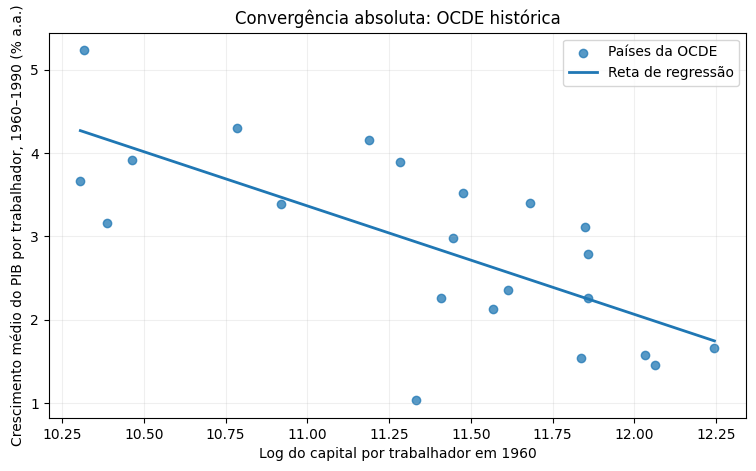

In [ ]:
reg_ocde = smf.ols("crescimento_medio_pct ~ ln_capital_inicial", data=amostra_ocde).fit()
print(reg_ocde.summary())

ordenado = amostra_ocde.sort_values("ln_capital_inicial").copy()
ordenado["ajustado"] = reg_ocde.predict(ordenado)

plt.figure(figsize=(9, 5))
plt.scatter(amostra_ocde["ln_capital_inicial"], amostra_ocde["crescimento_medio_pct"],
            alpha=0.75, label="Países da OCDE")
plt.plot(ordenado["ln_capital_inicial"], ordenado["ajustado"],
         linewidth=2, label="Reta de regressão")
plt.xlabel("Log do capital por trabalhador em 1960")
plt.ylabel("Crescimento médio do PIB por trabalhador, 1960–1990 (% a.a.)")
plt.title("Convergência absoluta: OCDE histórica")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 7. Regressão 2 — Amostra mundial filtrada

Agora repetiremos **exatamente a mesma especificação** para todos os países **restantes após o filtro de população**. Se a associação se enfraquecer, temos um problema para a hipótese de **convergência absoluta mundial**, mas **não necessariamente para o modelo de Solow**: os estados estacionários podem diferir entre países.

                              OLS Regression Results                             
Dep. Variable:     crescimento_medio_pct   R-squared:                       0.018
Model:                               OLS   Adj. R-squared:                  0.006
Method:                    Least Squares   F-statistic:                     1.485
Date:                   Sun, 15 Nov 2026   Prob (F-statistic):              0.226
Time:                           19:46:08   Log-Likelihood:                -168.89
No. Observations:                     85   AIC:                             341.8
Df Residuals:                         83   BIC:                             346.7
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Interc

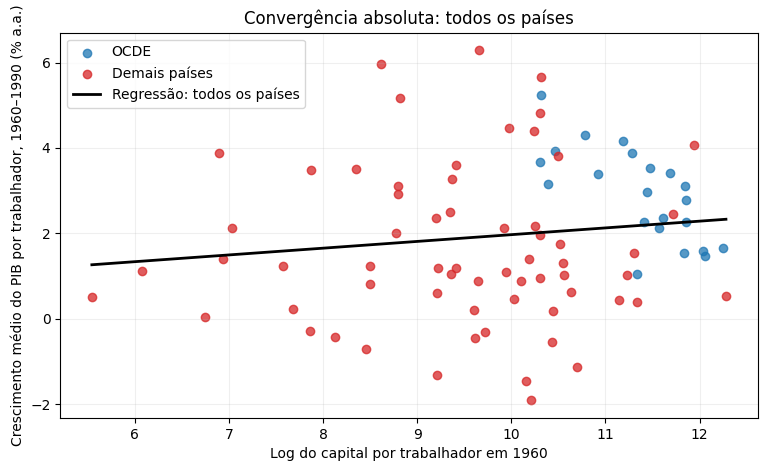

In [ ]:
reg_mundo = smf.ols("crescimento_medio_pct ~ ln_capital_inicial", data=amostra).fit()
print(reg_mundo.summary())

ordenado = amostra.sort_values("ln_capital_inicial")
ordenado["ajustado"] = reg_mundo.predict(ordenado)

plt.figure(figsize=(9, 5))

# Todos os países participam da mesma regressão; as cores apenas identificam os grupos.
plt.scatter(
    amostra_ocde["ln_capital_inicial"],
    amostra_ocde["crescimento_medio_pct"],
    color="tab:blue", alpha=0.75, label="OCDE"
)

outros_paises = amostra.loc[amostra["grupo"] == "Outros"]
plt.scatter(
    outros_paises["ln_capital_inicial"],
    outros_paises["crescimento_medio_pct"],
    color="tab:red", alpha=0.75, label="Demais países"
)

plt.plot(
    ordenado["ln_capital_inicial"], ordenado["ajustado"],
    color="black", linewidth=2, label="Regressão: todos os países"
)
plt.xlabel("Log do capital por trabalhador em 1960")
plt.ylabel("Crescimento médio do PIB por trabalhador, 1960–1990 (% a.a.)")
plt.title("Convergência absoluta: todos os países")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

                              OLS Regression Results                             
Dep. Variable:     crescimento_medio_pct   R-squared:                       0.000
Model:                               OLS   Adj. R-squared:                 -0.016
Method:                    Least Squares   F-statistic:                 5.607e-05
Date:                   Sun, 15 Nov 2026   Prob (F-statistic):              0.994
Time:                           19:46:09   Log-Likelihood:                -128.53
No. Observations:                     63   AIC:                             261.1
Df Residuals:                         61   BIC:                             265.3
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Interc

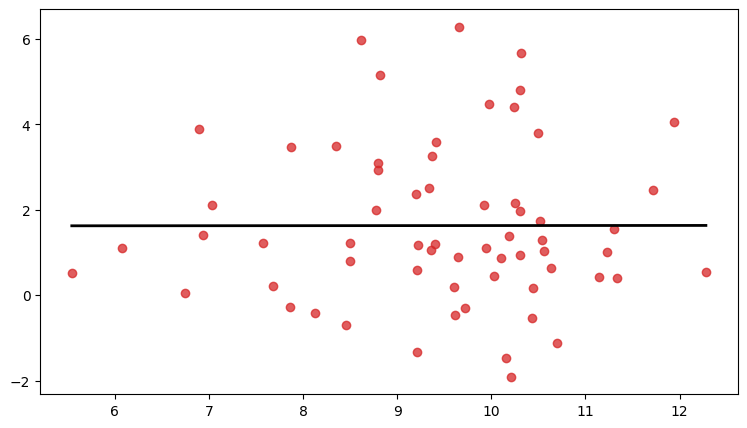

In [ ]:
reg_outros = smf.ols("crescimento_medio_pct ~ ln_capital_inicial", data=outros_paises).fit()
print(reg_outros.summary())

plt.figure(figsize=(9, 5))
plt.scatter(
    outros_paises["ln_capital_inicial"],
    outros_paises["crescimento_medio_pct"],
    color="tab:red", alpha=0.75, label="Demais países"
)

ordenado = outros_paises.sort_values("ln_capital_inicial").copy()
ordenado["ajustado"] = reg_outros.predict(ordenado)

plt.plot(
    ordenado["ln_capital_inicial"], ordenado["ajustado"],
    color="black", linewidth=2, label="Regressão: todos os países"
)

### 8. Quadro de comparação entre as duas regressões

In [ ]:
# Criamos um data-frame de forma muito parecida com um Dicionário:

comparacao = pd.DataFrame({
    "Amostra": ["OCDE", "Todos os países"],
    "Número de países": [int(reg_ocde.nobs), int(reg_mundo.nobs)],
    "Coeficiente do capital inicial": [
        reg_ocde.params["ln_capital_inicial"], reg_mundo.params["ln_capital_inicial"]
    ],
    "p-valor": [
        reg_ocde.pvalues["ln_capital_inicial"], reg_mundo.pvalues["ln_capital_inicial"]
    ],
    "R²": [reg_ocde.rsquared, reg_mundo.rsquared]
})

print(comparacao.round(4).to_string(index=False))

        Amostra  Número de países  Coeficiente do capital inicial  p-valor     R²
           OCDE                22                         -1.3015   0.0002 0.5039
Todos os países                85                          0.1583   0.2265 0.0176


## Parte III — Regressão múltipla: crescimento populacional e depreciação

**Pergunta:** a relação entre capital inicial e crescimento muda quando consideramos características diferentes entre os países?

Pelo modelo de Solow, a acumulação de capital por trabalhador efetivo é:

$$\frac{\dot{k}}{k}=s k^{\alpha-1}-(n+a+\delta).$$

Quanto maiores $n$ e $\delta$, **maior o investimento necessário para manter $k$ constante**, dado o mesmo nível de capital e os demais parâmetros. Isso altera o **nível do estado estacionário**:

$$k^*=\left(\frac{s}{n+a+\delta}\right)^{\frac{1}{1-\alpha}}.$$

**Atenção:** assim como a taxa de poupança, $n$ e $\delta$ afetam o **nível de renda de longo prazo** e o **crescimento de transição**. Com progresso tecnológico exógeno, **não alteram permanentemente o crescimento do produto por trabalhador no estado estacionário**, que é $a$. Por isso, os coeficientes de uma regressão de crescimento de 1960–1990 não são efeitos permanentes nem necessariamente causais.



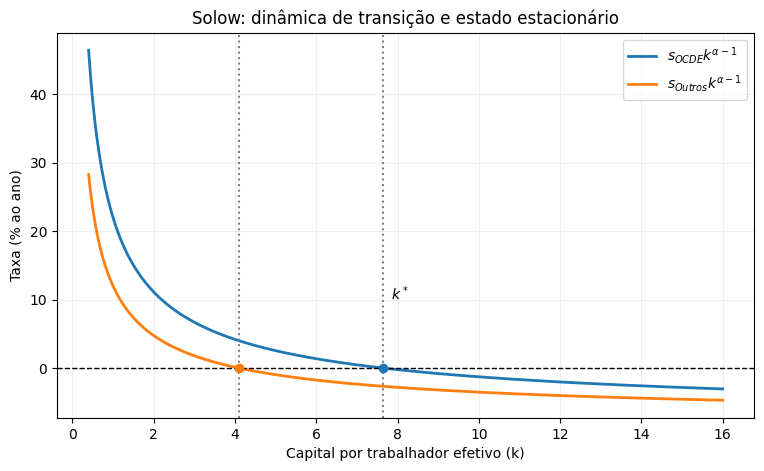

k_OCDE* = 7.64
k_Outros* = 4.09


In [ ]:
s_OCDE = 0.30
s_Outros = 0.2
alpha = 0.35
n = 0.01
a_OCDE = 0.02
a_Outros = 0.02
delta = 0.05


k_OCDE = pd.Series(range(300), dtype=float)

for i in range(300):
    k.iloc[i] = 0.4 + i * (16 - 0.4) / 299

linha_reposicao_OCDE = 100 * (n + a_OCDE + delta)
linha_reposicao_Outros = 100 * (n + a_Outros + delta)
curva_investimento_OCDE =  (100 * s_OCDE * k ** (alpha - 1) - linha_reposicao_OCDE)
curva_investimento_Outros =  ( 100 * s_Outros * k ** (alpha - 1) - linha_reposicao_Outros)

k_estrela_OCDE = (s_OCDE / (n + a + delta)) ** (1 / (1 - alpha))
k_estrela_Outros = (s_Outros / (n + a + delta)) ** (1 / (1 - alpha))


plt.figure(figsize=(9, 5))
plt.plot(k, curva_investimento_OCDE, linewidth=2, label=r"$s_{OCDE} k^{\alpha-1}$")
plt.plot(k, curva_investimento_Outros, linewidth=2, label=r"$s_{Outros} k^{\alpha-1}$")
plt.axhline(0, linestyle="--", linewidth=1, color="black")
plt.axvline(k_estrela_OCDE, linestyle=":", color="gray")
plt.axvline(k_estrela_Outros, linestyle=":", color="gray")
plt.scatter([k_estrela_OCDE], [0], zorder=5)
plt.scatter([k_estrela_Outros], [0], zorder=5)
plt.text(k_estrela + .2, linha_reposicao + 2, r"$k^*$")
plt.xlabel("Capital por trabalhador efetivo (k)")
plt.ylabel("Taxa (% ao ano)")
plt.title("Solow: dinâmica de transição e estado estacionário")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"k_OCDE* = {k_estrela_OCDE:.2f}")
print(f"k_Outros* = {k_estrela_Outros:.2f}")


## Parte III — Regressão múltipla: crescimento populacional e depreciação


Usaremos informações da **Penn World Table**:

- **Crescimento populacional inicial ($n_i$):** taxa geométrica anual entre **1960 e 1965**, usando `pop`; é uma aproximação do crescimento do trabalho do modelo.
- **Depreciação ($\delta_i$):** variável `delta` de **1960**, convertida de proporção para porcentagem.

Estimaremos três modelos **com o mesmo conjunto de países**:

$$
\begin{aligned}
\text{(1)}\quad &\overline g_i=\beta_0+\beta_1\ln(K/L)_{i,1960}+\varepsilon_i\\
\text{(2)}\quad &\overline g_i=\beta_0+\beta_1\ln(K/L)_{i,1960}+\beta_2 n_i+\varepsilon_i\\
\text{(3)}\quad &\overline g_i=\beta_0+\beta_1\ln(K/L)_{i,1960}+\beta_2 n_i+\beta_3\delta_i+\varepsilon_i.
\end{aligned}
$$

**Intuição:** mantidas constantes as demais características do modelo, esperamos que maiores $n$ e $\delta$ reduzam o crescimento durante a transição. Os resultados empíricos, porém, podem diferir por fatores omitidos, como tecnologia, investimentos e instituições.


In [ ]:
# Preciso recriar tudo, pois não temos dados para "delta" de 1960. Escolhendo 1965 como ano inicial:

# 1. Preparar as duas tabelas: uma com 1965, outra com 1990.

ano_inicial = 1965
ano_final = 1990

inicio = dados.loc[dados["year"] == ano_inicial, [
    "countrycode", "country", "capital_trabalhador", "produto_trabalhador", "hc", "pop","delta"
]]

fim = dados.loc[dados["year"] == ano_final, [
    "countrycode", "country", "capital_trabalhador", "produto_trabalhador", "hc", "pop","delta"
]]

# 2. Juntar pelo código: cada país fica com valores dos dois anos.
amostra = inicio.merge(fim, on="countrycode", how="inner", validate="one_to_one", suffixes=(f"_{ano_inicial}", f"_{ano_final}"))

amostra = amostra.dropna()

# 3 . Retirar NaNs, nulos e valores pequenos

amostra = amostra.loc[
    (amostra["capital_trabalhador_1965"] > 0) &
    (amostra["produto_trabalhador_1965"] > 0) &
    (amostra["produto_trabalhador_1990"] > 0) &
    (amostra["pop_1965"] > 1) &
    (amostra["pop_1990"].notna()) &
    (amostra["delta_1965"] >= 0) &
    (amostra["delta_1990"] >= 0)
]

# 4. Criação de coluna ln_capital
amostra["ln_capital_inicial"] = amostra["capital_trabalhador_1965"].map(math.log)

# Taxa média geométrica anual (em %) entre 1960 e 1990.

# Produto por trabalhador
amostra["crescimento_medio_pct_pib"] = 100 * (
    (amostra["produto_trabalhador_1990"] / amostra["produto_trabalhador_1965"])
    ** (1 / (ano_final - ano_inicial)) - 1
)

# Crescimento pop
amostra["crescimento_medio_pct_pop"] = 100 * (
    (amostra["pop_1990"] / amostra["pop_1965"])
    ** (1 / (ano_final - ano_inicial)) - 1
)

# Taxa depreciação em pct:
amostra["delta_1965_pct"] =  100 * amostra["delta_1965"]


display(amostra)

,countrycode,country_1965,capital_trabalhador_1965,produto_trabalhador_1965,hc_1965,pop_1965,delta_1965,country_1990,capital_trabalhador_1990,produto_trabalhador_1990,hc_1990,pop_1990,delta_1990,ln_capital_inicial,crescimento_medio_pct_pib,crescimento_medio_pct_pop,delta_1965_pct
5,ARG,Argentina,17906.545636,47633.476763,2.009806,22.205000,0.035214,Argentina,62266.394537,45821.972646,2.529030,32.755901,0.029883,9.792922,-0.154968,1.567217,3.521371
8,AUS,Australia,187001.799205,57717.101509,2.855409,11.384493,0.024742,Australia,293944.202842,80315.944801,3.411077,17.126298,0.026659,12.138874,1.330431,1.646866,2.474235
9,AUT,Austria,71113.686163,41889.133717,2.521375,7.270142,0.036569,Austria,297993.542501,91968.376229,2.965150,7.679624,0.036327,11.172035,3.195673,0.219419,3.656870
12,BEL,Belgium,160881.312021,48078.115404,2.314736,9.440947,0.040147,Belgium,286600.747501,98773.830800,2.758062,9.960968,0.039336,11.988422,2.921896,0.214702,4.014659
14,BFA,Burkina Faso,1126.664694,1440.549076,1.007223,5.322311,0.038759,Burkina Faso,4533.784154,2420.960582,1.029605,9.159356,0.038613,7.027017,2.098271,2.195221,3.875881
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,USA,United States,231116.916473,64741.116587,2.897152,196.903470,0.033067,United States,318287.306187,89403.150405,3.435097,253.373387,0.036303,12.350679,1.299408,1.013706,3.306725
178,VEN,Venezuela (Bolivarian Republic of),83135.004343,1697.031704,1.329749,9.598559,0.043785,Venezuela (Bolivarian Republic of),118576.795688,1525.523037,1.814335,19.827010,0.034111,11.328221,-0.425267,2.944239,4.378517
182,ZAF,South Africa,36844.024120,21495.993805,1.766281,19.495781,0.038501,South Africa,75177.795227,29539.320687,1.907844,40.746268,0.042556,10.514449,1.279540,2.992568,3.850060
183,ZMB,Zambia,15828.452367,9120.936264,1.335501,3.754911,0.030030,Zambia,17267.749809,7224.183278,1.830886,7.786169,0.037164,9.669564,-0.928218,2.960102,3.002960


In [ ]:
display(amostra[[
    "crescimento_medio_pct_pib",
    "capital_trabalhador_1965",
    "crescimento_medio_pct_pop",
    "delta_1965_pct"
]].head(10))

,crescimento_medio_pct_pib,capital_trabalhador_1965,crescimento_medio_pct_pop,delta_1965_pct
5,-0.154968,17906.545636,1.567217,3.521371
8,1.330431,187001.799205,1.646866,2.474235
9,3.195673,71113.686163,0.219419,3.656870
12,2.921896,160881.312021,0.214702,4.014659
14,2.098271,1126.664694,2.195221,3.875881
15,-0.371380,2640.049205,2.391420,3.367167
23,0.018906,11960.303676,2.268636,3.620643
24,1.645225,23183.095123,2.380609,4.879540
30,1.253573,154586.583228,1.368190,3.522364
31,1.291677,196343.263664,0.544228,4.796450


### 9. Regressão com duas e três variáveis explicativas

Os dados já estão organizados em **uma linha por país**. No `statsmodels`, basta acrescentar novas variáveis depois do símbolo `+` na fórmula de regressão.

- **Modelo 1:** capital inicial, como na comparação OCDE × mundo.
- **Modelo 2:** capital inicial **e** crescimento populacional.
- **Modelo 3:** capital inicial, crescimento populacional **e** depreciação.

Observe como mudam o coeficiente do capital, os sinais dos controles, o número de observações e o $R^2$. **O $R^2$ não diminui ao acrescentar regressores** em MQO com intercepto na mesma amostra; isso, isoladamente, não prova que o modelo seja melhor.


In [ ]:
# As três regressões usam exatamente os mesmos países.
reg_1 = smf.ols(
    "crescimento_medio_pct_pib ~ ln_capital_inicial", data=amostra
).fit()

reg_2 = smf.ols(
    "crescimento_medio_pct_pib ~ ln_capital_inicial + crescimento_medio_pct_pop", data=amostra
).fit()

reg_3 = smf.ols(
    "crescimento_medio_pct_pib ~ ln_capital_inicial + crescimento_medio_pct_pop + delta_1965_pct",
    data=amostra
).fit()

print("MODELO 1 — Apenas capital inicial")
print(reg_1.summary())

print("MODELO 2 — Capital inicial e crescimento populacional")
print(reg_2.summary())

print("MODELO 3 — Capital inicial, crescimento populacional e depreciação")
print(reg_3.summary())

comparacao_controles = pd.DataFrame({
    "Modelo": ["Capital", "Capital + população", "Capital + população + depreciação"],
    "Países": [int(reg_1.nobs), int(reg_2.nobs), int(reg_3.nobs)],
    "R2": [reg_1.rsquared, reg_2.rsquared, reg_3.rsquared],
    "R2 ajustado": [reg_1.rsquared_adj, reg_2.rsquared_adj, reg_3.rsquared_adj]
})
print(comparacao_controles.round(3))

MODELO 1 — Apenas capital inicial
                                OLS Regression Results                               
Dep. Variable:     crescimento_medio_pct_pib   R-squared:                       0.011
Model:                                   OLS   Adj. R-squared:                 -0.002
Method:                        Least Squares   F-statistic:                    0.8397
Date:                       Sun, 15 Nov 2026   Prob (F-statistic):              0.362
Time:                               19:46:09   Log-Likelihood:                -166.23
No. Observations:                         81   AIC:                             336.5
Df Residuals:                             79   BIC:                             341.2
Df Model:                                  1                                         
Covariance Type:                   nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-------------------

**Questões p/ análise:**

1. O coeficiente do capital inicial muda quando incluímos o crescimento populacional?
2. O crescimento populacional e a depreciação têm os sinais esperados? São estatisticamente significantes?
3. Qual é a diferença entre interpretar o efeito de uma variável **mantendo as demais constantes** e analisar uma correlação simples?
4. Qual modelo tem maior R² ajustado? Por que é importante comparar a mesma amostra?
5. Essas variáveis alteram o crescimento **no estado estacionário** ou principalmente o crescimento **durante a transição**?


## Parte IV — Exercício dos alunos: escolaridade e capital humano

A PWT inclui `hc`, um **índice de capital humano construído a partir de escolaridade e retornos à educação**. Ele **não mede diretamente anos médios de estudo**. Vamos usá-lo como *proxy* de escolaridade, pois está na mesma base.

Agora que já vimos regressões com **duas e três variáveis explicativas**, vamos fazer um exercício semelhante com o capital humano.

Crie duas novas variáveis:

$$\ln(hc_{i,1960}) \quad\text{e}\quad \overline{g}_{hc,i}=100\left[\left(\frac{hc_{i,1990}}{hc_{i,1960}}\right)^{1/30}-1\right].$$

**Exercício 1 — Nível inicial:** estime uma regressão de crescimento do produto por trabalhador contra log de capital inicial **e** log de capital humano inicial.

**Exercício 2 — Crescimento do capital humano:** substitua log do capital humano inicial pelo crescimento anual do índice entre 1960 e 1990.

**Exercício 3 — Compare** as regressões: sinal das variáveis, $R^2$, tamanho da amostra e relação com a hipótese de convergência condicional.

**Pergunta para discussão:** por que a variação de capital humano durante 1960–1990 pode ser simultaneamente causa e consequência do crescimento econômico? Por que essa associação não prova causalidade?

In [ ]:

# EXERCÍCIO — CAPITAL HUMANO E CONVERGÊNCIA

# 1. Crie um DataFrame "escola" a partir de "amostra".
# Mantenha apenas os países com hc_1965 e hc_1990 informados e maiores que zero.


# 2. Calcule o logaritmo do capital humano inicial.
# Crie a coluna "ln_hc_inicial".


# 3. Calcule a Taxa de Crescimento Anual Composta
# do capital humano entre 1965 e 1990.
# Crie a coluna "crescimento_hc_pct".


# 4. Estime três regressões por MQO:

# MODELO 1: Capital físico inicial + capital humano inicial
# reg_escola_nivel = smf.ols("...", data=escola).fit()

# MODELO 2: Capital físico inicial + crescimento do capital humano
# reg_escola_crescimento = smf.ols("...", data=escola).fit()

# MODELO 3: Capital físico inicial + crescimento do capital humano
#           + crescimento populacional
# reg_escola_completo = smf.ols("...", data=escola).fit()


# 5. Compare os três modelos:
# a) Qual apresenta maior R² ajustado?
# b) O coeficiente do capital físico inicial muda de sinal?
# c) O capital humano apresenta coeficiente significativo?
# d) Os resultados são compatíveis com a convergência condicional?


Países com dados de capital humano: 81
                                OLS Regression Results                               
Dep. Variable:     crescimento_medio_pct_pib   R-squared:                       0.147
Model:                                   OLS   Adj. R-squared:                  0.125
Method:                        Least Squares   F-statistic:                     6.703
Date:                       Sun, 15 Nov 2026   Prob (F-statistic):            0.00206
Time:                               19:47:48   Log-Likelihood:                -160.23
No. Observations:                         81   AIC:                             326.5
Df Residuals:                             78   BIC:                             333.6
Df Model:                                  2                                         
Covariance Type:                   nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------

## Parte V — Extensão opcional: mudar o período para 1990–2023

Como a PWT 11.0 vai até 2023, uma extensão interessante é testar se os resultados persistem ao avaliarmos a janela de 1990 até 2023


In [ ]:

import math

# EXERCÍCIO — CONVERGÊNCIA ECONÔMICA (1990–2023)

# 1 - Crie dois DataFrames a partir de "dados":
#     um contendo apenas o ano de 1990 ("inicio") e
#     outro contendo apenas o ano de 2023 ("fim").
#     Dica: utilize .loc[].


# 2 - Combine os dois DataFrames em uma única base, chamada "amostra_2023".
#     Utilize "countrycode" para identificar os países.
#     Mantenha apenas países presentes nos dois anos.
#     Dica: utilize .merge() e suffixes=("_1990", "_2023"). Utilize os exemplos já usados acima.


# 3 - Retire os países com dados ausentes nas variáveis:
#     - capital_trabalhador_1990
#     - produto_trabalhador_1990
#     - produto_trabalhador_2023
#     - pop_1990
#     Dica: utilize .dropna().


# 4 - Exclua os países que apresentam:
#     - Capital por trabalhador em 1990 menor ou igual a zero;
#     - Produto por trabalhador em 1990 menor ou igual a zero;
#     - Produto por trabalhador em 2023 menor ou igual a zero;
#     - População em 1990 menor ou igual a 1.
#     Dica: utilize .loc[] e o operador &.


# 5 - Crie a variável "ln_capital_inicial",
#     calculando o logaritmo natural de
#     "capital_trabalhador_1990".
#     Dica: utilize .map(math.log).


# 6 - Calcule a taxa de crescimento médio anual do
#     produto por trabalhador entre 1990 e 2023.
#     Salve em "crescimento_medio_pct_pib".
#     Dica: utilize a fórmula da taxa de crescimento
#     anual composta (CAGR), multiplicada por 100.


# 7 - Identifique os países que pertenciam à OCDE em 1990.
#     Crie uma coluna chamada "grupo" em "amostra_2023",
#     classificando os países como "OCDE" ou "Outros".
#     Dica: utilize .isin(ocde_1990) e .map().


# 8 - Crie um novo DataFrame chamado "amostra_ocde_2023",
#     contendo apenas os países classificados como "OCDE".
#     Dica: utilize .loc[].


# 9 - Estime uma regressão por MQO utilizando todos
#     os países de "amostra_2023".
#     Variável dependente: crescimento_medio_pct_pib
#     Variável explicativa: ln_capital_inicial
#     Salve o resultado em "reg_2023".
#     Dica: utilize smf.ols() e .fit().


# 10 - Repita a regressão utilizando apenas os países
#      da OCDE, presentes em "amostra_ocde_2023".
#      Salve o resultado em "reg_2023_ocde".


# 11 - Apresente os resultados das duas regressões.
#      Dica: utilize .summary().


# 12 - Compare os resultados e avalia se os resultados da regressão ao considerarmos períodos temporais diferentes.




,countrycode,country_1965,capital_trabalhador_1965,produto_trabalhador_1965,hc_1965,pop_1965,delta_1965,country_1990,capital_trabalhador_1990,produto_trabalhador_1990,hc_1990,pop_1990,delta_1990,ln_capital_inicial,crescimento_medio_pct_pib,crescimento_medio_pct_pop,delta_1965_pct,ln_hc_inicial,crescimento_hc_pct,grupo
8,AUS,Australia,187001.799205,57717.101509,2.855409,11.384493,0.024742,Australia,293944.202842,80315.944801,3.411077,17.126298,0.026659,12.138874,1.330431,1.646866,2.474235,1.049215,0.713787,OCDE
9,AUT,Austria,71113.686163,41889.133717,2.521375,7.270142,0.036569,Austria,297993.542501,91968.376229,2.965150,7.679624,0.036327,11.172035,3.195673,0.219419,3.656870,0.924805,0.650599,OCDE
12,BEL,Belgium,160881.312021,48078.115404,2.314736,9.440947,0.040147,Belgium,286600.747501,98773.830800,2.758062,9.960968,0.039336,11.988422,2.921896,0.214702,4.014659,0.839295,0.703393,OCDE
30,CAN,Canada,154586.583228,59783.846874,2.729551,19.785066,0.035224,Canada,308873.905837,81628.687108,3.290599,27.789443,0.035180,11.948510,1.253573,1.368190,3.522364,1.004137,0.750532,OCDE
31,CHE,Switzerland,196343.263664,90900.353064,3.083929,5.861372,0.047964,Switzerland,358689.295838,125288.044357,3.463197,6.713173,0.045359,12.187620,1.291677,0.544228,4.796450,1.126204,0.465028,OCDE
46,DEU,Germany,131402.981922,42305.737798,2.767674,75.999084,0.033827,Germany,252037.786550,81825.923103,3.430267,79.707959,0.033588,11.786024,2.673807,0.190774,3.382741,1.018007,0.862219,OCDE
49,DNK,Denmark,133868.761115,49434.447542,2.662928,4.758014,0.034508,Denmark,241492.412182,83446.696787,3.104338,5.141025,0.035043,11.804615,2.116325,0.310169,3.450814,0.979426,0.615382,OCDE
54,ESP,Spain,66751.956224,35478.445070,1.996887,32.024126,0.032595,Spain,242421.452561,84260.471917,2.430510,39.084979,0.032260,11.108739,3.520503,0.800179,3.259458,0.691590,0.789144,OCDE
57,FIN,Finland,124344.253979,31746.599320,2.301806,4.563730,0.034613,Finland,305173.457126,72728.399210,2.960033,4.986575,0.038019,11.730809,3.371370,0.355065,3.461339,0.833694,1.011103,OCDE
59,FRA,France,151975.184431,43524.597550,2.212104,49.886984,0.025060,France,298347.632370,90947.468924,2.801134,58.604902,0.029446,11.931473,2.991702,0.646313,2.506035,0.793944,0.948795,OCDE


Extensão 1990–2023 — todos os países:
                                OLS Regression Results                               
Dep. Variable:     crescimento_medio_pct_pib   R-squared:                       0.139
Model:                                   OLS   Adj. R-squared:                  0.133
Method:                        Least Squares   F-statistic:                     22.69
Date:                       Sun, 15 Nov 2026   Prob (F-statistic):           4.71e-06
Time:                               19:55:26   Log-Likelihood:                -270.93
No. Observations:                        142   AIC:                             545.9
Df Residuals:                            140   BIC:                             551.8
Df Model:                                  1                                         
Covariance Type:                   nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
---------------

## Fechamento: o que cada regressão testa?

| Exercício | Variável explicativa | Interpretação |
|---|---|---|
| OCDE, 1960–1990 | $\ln(K/L)_{1960}$ | Teste de convergência absoluta em grupo mais homogêneo |
| Mundo, 1960–1990 | $\ln(K/L)_{1960}$ | Teste de convergência absoluta em amostra mundial |
| Mundo — dois regressores | $\ln(K/L)_{1960}$ e crescimento populacional 1960–1965 | Introdução ao MQO múltiplo: verificar a associação parcial |
| Mundo — três regressores | $\ln(K/L)_{1960}$, crescimento populacional e depreciação de 1960 | Discutir condições estruturais diferentes e crescimento de transição |
| Capital humano — nível (exercício) | $\ln(K/L)_{1960}$ e $\ln(hc_{1960})$ | Investigar se controlar pelo capital humano inicial altera o resultado |
| Capital humano — crescimento (exercício) | $\ln(K/L)_{1960}$ e $g_{hc,1960–1990}$ | Associação entre crescimento e acumulação de capital humano (possível endogeneidade) |

**Ideia principal:** características diferentes podem alterar o estado estacionário dos países e, com isso, a dinâmica de transição. Crescimento populacional e depreciação não determinam o crescimento de longo prazo por trabalhador no modelo básico de Solow com progresso tecnológico exógeno. As regressões são descritivas; não estabelecem causalidade.

### Referências

- Jones, Charles I. *Introdução à teoria do crescimento econômico*, capítulo 3 (trecho enviado, especialmente p. 55).
- Solow, Robert M. (1956). *A Contribution to the Theory of Economic Growth*. QJE.
- Mankiw, N. G., Romer, D. e Weil, D. (1992). *A Contribution to the Empirics of Economic Growth*. QJE.
- Feenstra, R., Inklaar, R. e Timmer, M. (2015). *The Next Generation of the Penn World Table*. AER.
- [PWT 11.0 — Universidade de Groningen](https://www.rug.nl/ggdc/productivity/pwt/).
- [OCDE — histórico de adesões](https://www.oecd.org/en/about/legal.html).

In [ ]:

#@title GABARITO — Capital humano e convergência { display-mode: "form" }

mostrar_gabarito = False #@param {type:"boolean"}

if mostrar_gabarito:

    # EXERCÍCIOS 1 A 3 — Preparação dos dados

    escola = amostra.dropna(subset=[
        "hc_1965",
        "hc_1990",
        "ln_capital_inicial",
        "crescimento_medio_pct_pib",
        "crescimento_medio_pct_pop"
    ]).copy()

    escola = escola.loc[
        (escola["hc_1965"] > 0) &
        (escola["hc_1990"] > 0)
    ].copy()

    # Logaritmo do capital humano inicial
    escola["ln_hc_inicial"] = (
        escola["hc_1965"].map(math.log)
    )

    # Taxa média geométrica de crescimento do capital humano
    escola["crescimento_hc_pct"] = 100 * (
        (escola["hc_1990"] / escola["hc_1965"])
        ** (1 / (ano_final - ano_inicial)) - 1
    )

    print("Países na amostra:", len(escola))

    display(escola[[
        "countrycode",
        "ln_capital_inicial",
        "ln_hc_inicial",
        "crescimento_hc_pct",
        "crescimento_medio_pct_pib"
    ]].head(10))


    # EXERCÍCIO 4 — REGRESSÕES

    # Modelo 1: Nível inicial de capital humano
    reg_escola_nivel = smf.ols(
        "crescimento_medio_pct_pib ~ ln_capital_inicial + ln_hc_inicial",
        data=escola
    ).fit()

    print("\nMODELO 1 — Capital humano inicial")
    print(reg_escola_nivel.summary())


    # Modelo 2: Crescimento do capital humano
    reg_escola_crescimento = smf.ols(
        "crescimento_medio_pct_pib ~ ln_capital_inicial + crescimento_hc_pct",
        data=escola
    ).fit()

    print("\nMODELO 2 — Crescimento do capital humano")
    print(reg_escola_crescimento.summary())


    # Modelo 3: Acrescentando crescimento populacional
    reg_escola_completo = smf.ols(
        "crescimento_medio_pct_pib ~ ln_capital_inicial + crescimento_hc_pct + crescimento_medio_pct_pop",
        data=escola
    ).fit()

    print("\nMODELO 3 — Capital humano e população")
    print(reg_escola_completo.summary())


    # EXERCÍCIO 5 — Comparação dos modelos

    comparacao = pd.DataFrame({
        "Modelo": [
            "Capital humano inicial",
            "Crescimento do capital humano",
            "Capital humano + população"
        ],
        "Países": [
            int(reg_escola_nivel.nobs),
            int(reg_escola_crescimento.nobs),
            int(reg_escola_completo.nobs)
        ],
        "R² ajustado": [
            reg_escola_nivel.rsquared_adj,
            reg_escola_crescimento.rsquared_adj,
            reg_escola_completo.rsquared_adj
        ],
        "Coef. capital inicial": [
            reg_escola_nivel.params["ln_capital_inicial"],
            reg_escola_crescimento.params["ln_capital_inicial"],
            reg_escola_completo.params["ln_capital_inicial"]
        ],
        "p-valor capital inicial": [
            reg_escola_nivel.pvalues["ln_capital_inicial"],
            reg_escola_crescimento.pvalues["ln_capital_inicial"],
            reg_escola_completo.pvalues["ln_capital_inicial"]
        ]
    })

    display(comparacao.round(4))


Países na amostra: 81


,countrycode,ln_capital_inicial,ln_hc_inicial,crescimento_hc_pct,crescimento_medio_pct_pib
5,ARG,9.792922,0.698038,0.923427,-0.154968
8,AUS,12.138874,1.049215,0.713787,1.330431
9,AUT,11.172035,0.924805,0.650599,3.195673
12,BEL,11.988422,0.839295,0.703393,2.921896
14,BFA,7.027017,0.007197,0.087950,2.098271
15,BGD,7.878553,0.144921,0.946190,-0.371380
23,BOL,9.389348,0.446308,1.314100,0.018906
24,BRA,10.051179,0.371123,0.679402,1.645225
30,CAN,11.948510,1.004137,0.750532,1.253573
31,CHE,12.187620,1.126204,0.465028,1.291677



MODELO 1 — Capital humano inicial
                                OLS Regression Results                               
Dep. Variable:     crescimento_medio_pct_pib   R-squared:                       0.147
Model:                                   OLS   Adj. R-squared:                  0.125
Method:                        Least Squares   F-statistic:                     6.703
Date:                       Sun, 15 Nov 2026   Prob (F-statistic):            0.00206
Time:                               20:02:37   Log-Likelihood:                -160.23
No. Observations:                         81   AIC:                             326.5
Df Residuals:                             78   BIC:                             333.6
Df Model:                                  2                                         
Covariance Type:                   nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------

,Modelo,Países,R² ajustado,Coef. capital inicial,p-valor capital inicial
0,Capital humano inicial,81,0.1248,-0.3629,0.0573
1,Crescimento do capital humano,81,0.0823,0.0954,0.4685
2,Capital humano + população,81,0.3494,-0.2874,0.0286
